# Tahap 1. Pembersihan data MAUDE MRI


In [1]:
from pathlib import Path
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import sklearn
from scipy.sparse.csgraph import connected_components
from sklearn.feature_extraction.text import TfidfVectorizer

print("pandas", pd.__version__, "| scipy", scipy.__version__, "| sklearn", sklearn.__version__)

INPUT = Path("/kaggle/input")
if INPUT.exists():  # Kaggle: nama dataset bebas, file dicari di semua input yang terpasang
    ROOT = Path("/kaggle/working")
    temuan = sorted(INPUT.rglob("maude_mri_LNH.csv"))
else:  # lokal/Colab dari clone repo: pakai data/raw/ milik repo
    ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
    temuan = sorted((ROOT / "data/raw").glob("maude_mri_LNH.csv"))
if not temuan:
    raise FileNotFoundError("maude_mri_LNH.csv belum ada. Klik Add Input, lalu pilih dataset MAUDE-mu.")
RAW = temuan[0]
print("Data:", RAW)
TABEL = ROOT / "outputs/tables"
GAMBAR = ROOT / "outputs/figures"
for p in [TABEL, GAMBAR, ROOT / "data/interim"]:
    p.mkdir(parents=True, exist_ok=True)

KELAS = ["Injury", "Malfunction", "Death", "Other"]
WARNA = ["#0072B2", "#E69F00", "#000000", "#009E73"]

def bar_labels(ax, **kw):
    for c in ax.containers:
        ax.bar_label(c, padding=2, **kw)

pandas 3.1.0 | scipy 1.18.1 | sklearn 1.9.1
Data: C:\Users\user\AppData\Local\Temp\claude\94d9c0cdc08b670d\f20bb482-6464-4449-a91a-991e4ef97395\scratchpad\repo_maude\data\raw\maude_mri_LNH.csv


## 1.1 Muat data mentah

In [2]:
mentah = pd.read_csv(RAW, keep_default_na=False,
                     dtype={"mdr_report_key": str, "date_received": str})
assert len(mentah) == 4833, "File mentah berbeda dari unduhan 11 Nov 2026"
mentah.shape

(4833, 10)

In [3]:
pd.DataFrame({"kosong": (mentah == "").sum(), "nilai_unik": mentah.nunique()})

,kosong,nilai_unik
mdr_report_key,0,4833
report_number,0,4833
date_received,0,2568
event_type,89,5
report_source_code,0,4
manufacturer,91,273
brand_name,40,1097
event_text,81,4059
mfr_narrative,1326,2667
patient_outcome,2271,52


In [4]:
mentah.event_type.replace("", "(kosong)").value_counts()

event_type
Injury         2214
Malfunction    2104
Other           389
(kosong)         89
Death            37
Name: count, dtype: int64

## 1.2 Pilih kolom
X = `event_text`, y = `event_type`. Pendukung: `mdr_report_key`, `date_received`, `manufacturer`.

| Kolom dibuang | Alasan (kebocoran L2, Kapoor dan Narayanan 2023) |
|---|---|
| `patient_outcome` | Proksi label, lihat bukti di bawah |
| `mfr_narrative` | Ditulis setelah investigasi, belum tersedia saat laporan diklasifikasi |
| `report_source_code` | Metadata pelapor yang sebarannya berkaitan dengan label |
| `brand_name` | Identitas produk, model bisa menghafal produk alih-alih kejadian |

`report_number` juga tidak dipakai karena hanya nomor identitas.

In [5]:
pd.crosstab(mentah.patient_outcome.str.contains("Death").rename("outcome memuat Death"),
            mentah.event_type.replace("", "(kosong)"))

event_type,(kosong),Death,Injury,Malfunction,Other
outcome memuat Death,,,,,
False,89,1,2214,2104,389
True,0,36,0,0,0


Dari 37 laporan Death, 36 memuat "Death" di `patient_outcome`, dan tidak ada kelas lain yang memuatnya.

In [6]:
pd.crosstab(mentah.report_source_code, mentah.event_type.replace("", "(kosong)"))

event_type,(kosong),Death,Injury,Malfunction,Other
report_source_code,,,,,
Distributor report,1,2,45,11,36
Manufacturer report,10,28,1704,1936,267
User Facility report,41,2,43,82,20
Voluntary report,37,5,422,75,66


## Lonjakan 2025

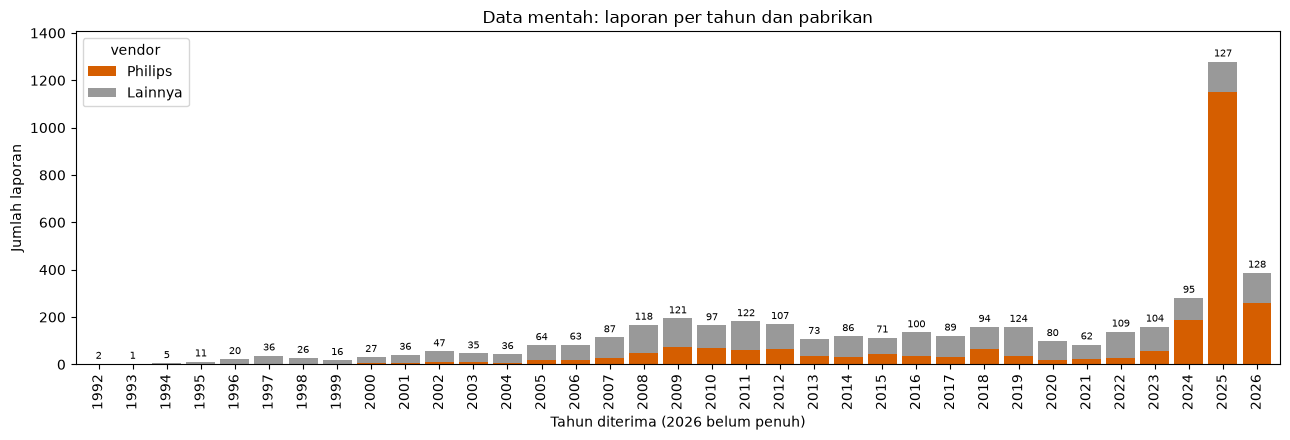

In [7]:
x = mentah.assign(
    tahun=mentah.date_received.str[:4],
    vendor=np.where(mentah.manufacturer.str.contains("philips", case=False), "Philips", "Lainnya"))
per_tahun = pd.crosstab(x.tahun, x.vendor)[["Philips", "Lainnya"]]
per_tahun.to_csv(TABEL / "01_vendor_per_tahun.csv")

fig, ax = plt.subplots(figsize=(13, 4.5))
per_tahun.plot.bar(stacked=True, ax=ax, color=["#D55E00", "#999999"], width=.85)
ax.bar_label(ax.containers[-1], fontsize=7, padding=2)
ax.set(xlabel="Tahun diterima (2026 belum penuh)", ylabel="Jumlah laporan",
       title="Data mentah: laporan per tahun dan pabrikan")
ax.margins(y=.1)
fig.tight_layout()
fig.savefig(GAMBAR / "01_vendor_per_tahun.png", dpi=150)
plt.show()

In [8]:
p25 = x[(x.tahun == "2025") & (x.vendor == "Philips")]
print("Philips 2025:", len(p25), p25.event_type.value_counts().to_dict())
print("Menyebut QUADRATURE BODY COIL:", p25.event_text.str.contains("QUADRATURE BODY COIL").sum())
p25.event_text.str[:110].value_counts().head().to_frame("jumlah")

Philips 2025: 1152 {'Malfunction': 1110, 'Injury': 42}
Menyebut QUADRATURE BODY COIL: 1021


,jumlah
event_text,
PHILIPS RECEIVED A REPORT THAT THE QUADRATURE BODY COIL (QBC) SEAL WAS LOOSE. THIS SEAL IS USED FOR PROTECTION,231
PHILIPS RECEIVED A REPORT THAT THE QUADRATURE BODY COIL (QBC) SEAL WAS DAMAGED. THIS SEAL IS USED FOR PROTECTI,157
PHILIPS RECEIVED A REPORT THAT THE QUADRATURE BODY COIL (QBC) SEAL WAS MISSING. THIS SEAL IS USED FOR PROTECTI,26
PHILIPS RECEIVED A REPORT THAT THE QUADRATURE BODY COIL (QBC) SEAL IS DAMAGED. THIS SEAL IS USED FOR PROTECTIO,25
"PHILIPS RECEIVED A REPORT THAT THE QUADRATURE BODY COIL (QBC) SEAL CAME OFF. THIS SEAL IS USED FOR PROTECTION,",21


Pada 2025 ada 1.279 laporan, 1.152 di antaranya dari Philips (1.110 Malfunction).
Pembukaan narasi yang paling sering adalah template segel Quadrature Body Coil (QBC).

In [9]:
AMBANG = 0.9
tahap = {}

def catat(nama, d):
    tahap[nama] = d.event_type.value_counts().reindex(KELAS, fill_value=0)
    print(f"{nama}: {len(d)} laporan")

In [10]:
df = mentah[["mdr_report_key", "date_received", "manufacturer", "event_text", "event_type"]].copy()

## 1.3 Saring label

In [11]:
df = df[df.event_type.isin(KELAS)].copy()
catat("Data mentah berlabel", df)

Data mentah berlabel: 4744 laporan


## 1.4 Saring narasi kurang dari 10 kata

In [12]:
df = df[df.event_text.str.split().str.len() >= 10].copy()
catat("Narasi minimal 10 kata", df)

Narasi minimal 10 kata: 4645 laporan


## 1.5 Buang duplikat persis
`norm` hanya berisi huruf kecil a–z dan spasi. Laporan paling awal dipertahankan.

In [13]:
df["norm"] = df.event_text.map(
    lambda s: re.sub(r"\s+", " ", re.sub(r"[^a-z]", " ", s.lower())).strip())
print("Teks identik dengan label berbeda:", (df.groupby("norm").event_type.nunique() > 1).sum())

df = (df.sort_values(["date_received", "mdr_report_key"])
        .drop_duplicates("norm")
        .reset_index(drop=True))
catat("Tanpa duplikat persis", df)

Teks identik dengan label berbeda: 0
Tanpa duplikat persis: 3856 laporan


## 1.6 Grup kemiripan lintas kelas
TF-IDF di sini hanya untuk mencari duplikat dan tidak dipakai model.

In [14]:
X = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True).fit_transform(df.norm)
S = (X @ X.T).tocsr()  # vektor sudah ternormalisasi L2, jadi hasil kali titik = cosine
S.data[S.data < AMBANG] = 0
S.eliminate_zeros()

n_grup, df["grup"] = connected_components(S, directed=False)

multi = df[df.groupby("grup").event_type.transform("nunique") > 1].sort_values("grup")
multi = multi[["grup", "mdr_report_key", "date_received", "manufacturer", "event_type", "event_text"]]
multi.to_csv(TABEL / "02_grup_multikelas.csv", index=False)
print("Jumlah grup:", n_grup, "| grup multi-kelas:", multi.grup.nunique())
multi

Jumlah grup: 3503 | grup multi-kelas: 2


,grup,mdr_report_key,date_received,manufacturer,event_type,event_text
71,65,144903,19980121,SIEMENS MEDICAL SYSTEMS,Other,THERMAL BURN TO LEFT FORARM DURING MRI. EXTRA ...
72,65,153437,19980228,"MEDIAL ADVANCES, INC.",Injury,THERMAL BURN TO LEFT FOREARM DURING MRI. EXTRA...
2461,2411,13937953,20220329,FUJIFILM HEALTHCARE CORPORATION,Injury,ON (B)(6) 2022 FUJIFILM HEALTHCARE AMERICAS CO...
2467,2411,14084517,20220412,FUJIFILM HEALTHCARE CORPORATION,Malfunction,"ON 03 MARCH 2022, FUJIFILM HEALTHCARE CORPORAT..."


Dua grup multi-kelas tampak menceritakan kejadian yang sama dengan label berbeda
(Fujifilm 2022: Injury dan Malfunction, luka bakar lengan 1998: Other dan Injury).
Daftarnya dipakai lagi di analisis kesalahan.

## 1.7 Buang duplikat mirip dalam kelas yang sama

In [15]:
label = df.event_type.to_numpy()
disimpan = np.zeros(len(df), dtype=bool)
for i in range(len(df)):  # df sudah urut waktu
    mirip = S.indices[S.indptr[i]:S.indptr[i + 1]]
    disimpan[i] = not np.any(disimpan[mirip] & (label[mirip] == label[i]))

df = df[disimpan].reset_index(drop=True)
catat("Akhir pembersihan", df)

Akhir pembersihan: 3604 laporan


### Ukuran grup setelah pembersihan
Grup bersifat transitif (A mirip B, B mirip C), jadi anggota yang tersisa bisa tetap satu grup
walaupun antaranggotanya sendiri di bawah 0,9.

In [16]:
ukuran = df.grup.value_counts()
besar = df[df.grup == ukuran.index[0]]
print(ukuran.head().to_dict())
print(besar.event_type.value_counts().to_dict())
print(besar.date_received.str[:4].value_counts().sort_index().to_dict())
print(besar.manufacturer.value_counts().to_dict())
print(besar.event_text.iloc[0][:600])

{2730: 90, 1182: 3, 3330: 3, 48: 2, 65: 2}
{'Malfunction': 90}
{'2024': 12, '2025': 72, '2026': 6}
{'PHILIPS ELECTRONICS NEDERLAND B.V.': 73, 'PHILIPS MEDICAL SYSTEMS NEDERLAND B.V.': 15, 'PHILIPS NORTH AMERICA LLC': 1, 'Philips Medical Systems Nederland B.V.': 1}
PHILIPS RECEIVED A REPORT THAT THE QUADRATURE BODY COIL (QBC) SEAL WAS LOOSE. THIS SEAL IS USED FOR PROTECTION, TO AVOID THE PATIENT FROM POTENTIALLY CONTACTING THE SHARP EDGES OF THE MAGNET COVERS. IF THIS SEAL IS LOOSE IT IS LIKELY THAT THIS COULD LEAD TO SERIOUS INJURY.


## 1.8 Tabel dan grafik tahap pembersihan

In [17]:
tab = pd.DataFrame(tahap).T
tab["Total"] = tab.sum(axis=1)
tab.index.name = "Tahap"
tab.to_csv(TABEL / "02_tahap_pembersihan.csv")
tab

event_type,Injury,Malfunction,Death,Other,Total
Tahap,,,,,
Data mentah berlabel,2214,2104,37,389,4744
Narasi minimal 10 kata,2201,2061,36,347,4645
Tanpa duplikat persis,2178,1296,36,346,3856
Akhir pembersihan,2144,1082,36,342,3604


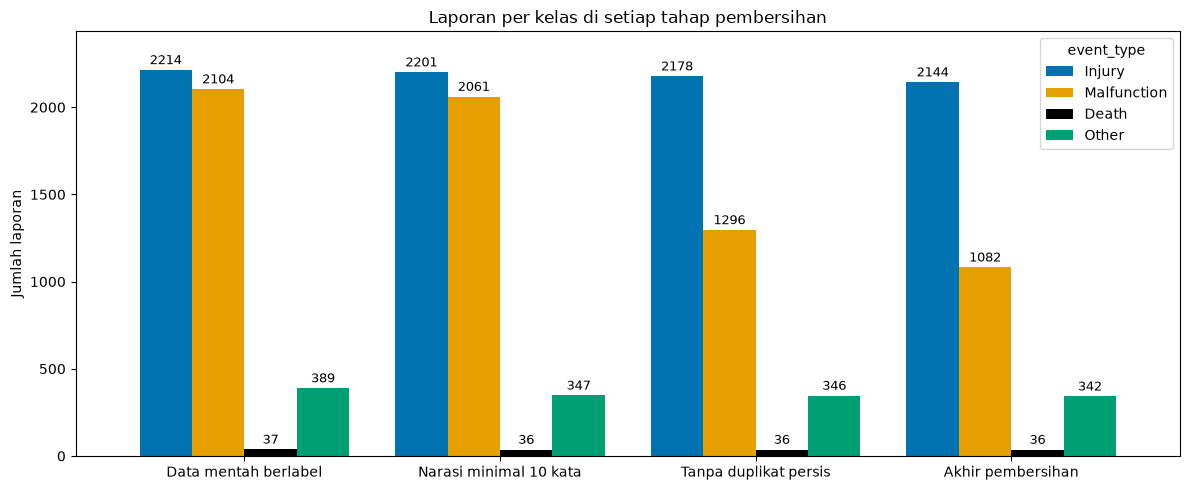

In [18]:
fig, ax = plt.subplots(figsize=(12, 5))
tab[KELAS].plot.bar(ax=ax, rot=0, color=WARNA, width=.82)
bar_labels(ax, fontsize=9)
ax.set(xlabel="", ylabel="Jumlah laporan", title="Laporan per kelas di setiap tahap pembersihan")
ax.margins(y=.1)
fig.tight_layout()
fig.savefig(GAMBAR / "02_tahap_pembersihan.png", dpi=150)
plt.show()

## 1.9 EDA
### Sebaran kelas

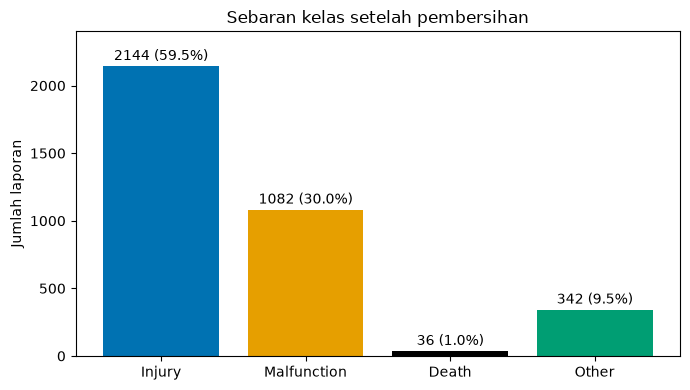

In [19]:
vc = df.event_type.value_counts().reindex(KELAS)
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(KELAS, vc, color=WARNA)
ax.bar_label(ax.containers[0], labels=[f"{v} ({v / len(df):.1%})" for v in vc], padding=2)
ax.set(ylabel="Jumlah laporan", title="Sebaran kelas setelah pembersihan")
ax.margins(y=.12)
fig.tight_layout()
fig.savefig(GAMBAR / "02_sebaran_kelas.png", dpi=150)
plt.show()

### Kelas per periode tahun

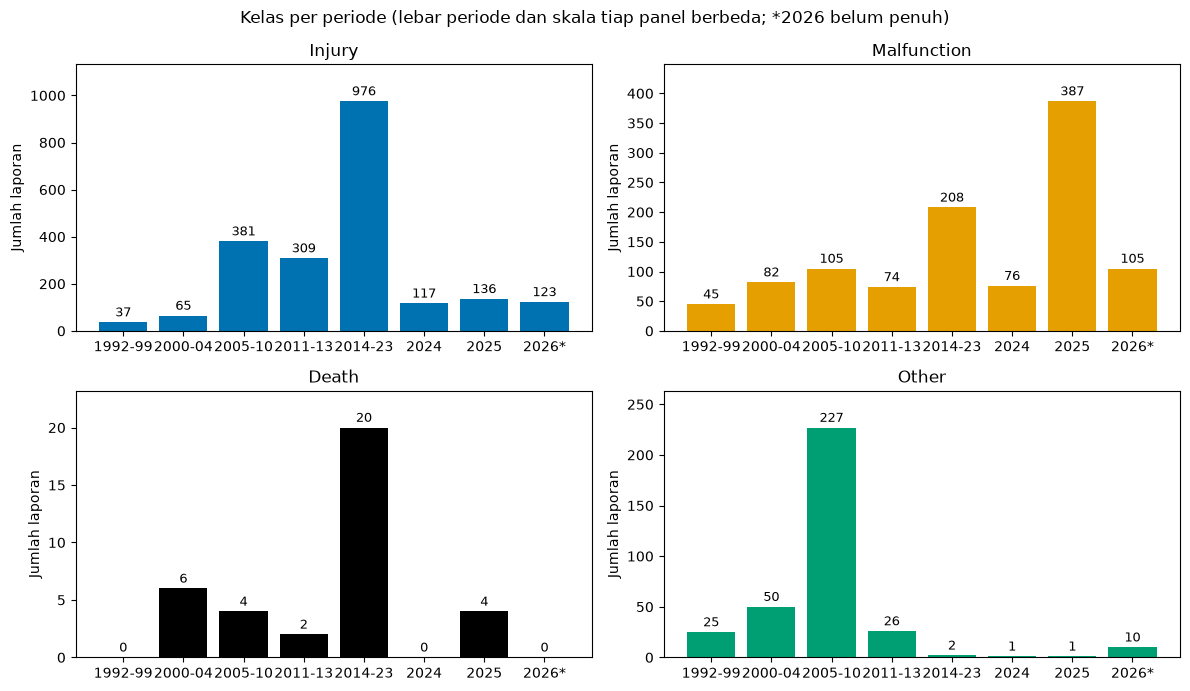

event_type,Injury,Malfunction,Death,Other
periode,,,,
1992-99,37,45,0,25
2000-04,65,82,6,50
2005-10,381,105,4,227
2011-13,309,74,2,26
2014-23,976,208,20,2
2024,117,76,0,1
2025,136,387,4,1
2026*,123,105,0,10


In [20]:
tahun = df.date_received.str[:4].astype(int).rename("tahun")
pd.crosstab(tahun, df.event_type)[KELAS].to_csv(TABEL / "02_kelas_per_tahun.csv")

periode = pd.cut(tahun, [1991, 1999, 2004, 2010, 2013, 2023, 2024, 2025, 2026],
                 labels=["1992-99", "2000-04", "2005-10", "2011-13", "2014-23", "2024", "2025", "2026*"])
cp = pd.crosstab(periode.rename("periode"), df.event_type)[KELAS]
cp.to_csv(TABEL / "02_kelas_per_periode.csv")

fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for ax, k, w in zip(axes.flat, KELAS, WARNA):
    ax.bar(cp.index.astype(str), cp[k], color=w)
    bar_labels(ax, fontsize=9)
    ax.set(title=k, ylabel="Jumlah laporan")
    ax.margins(y=.16)
fig.suptitle("Kelas per periode (lebar periode dan skala tiap panel berbeda; *2026 belum penuh)")
fig.tight_layout()
fig.savefig(GAMBAR / "02_kelas_per_periode.png", dpi=150)
plt.show()
cp

### Panjang narasi

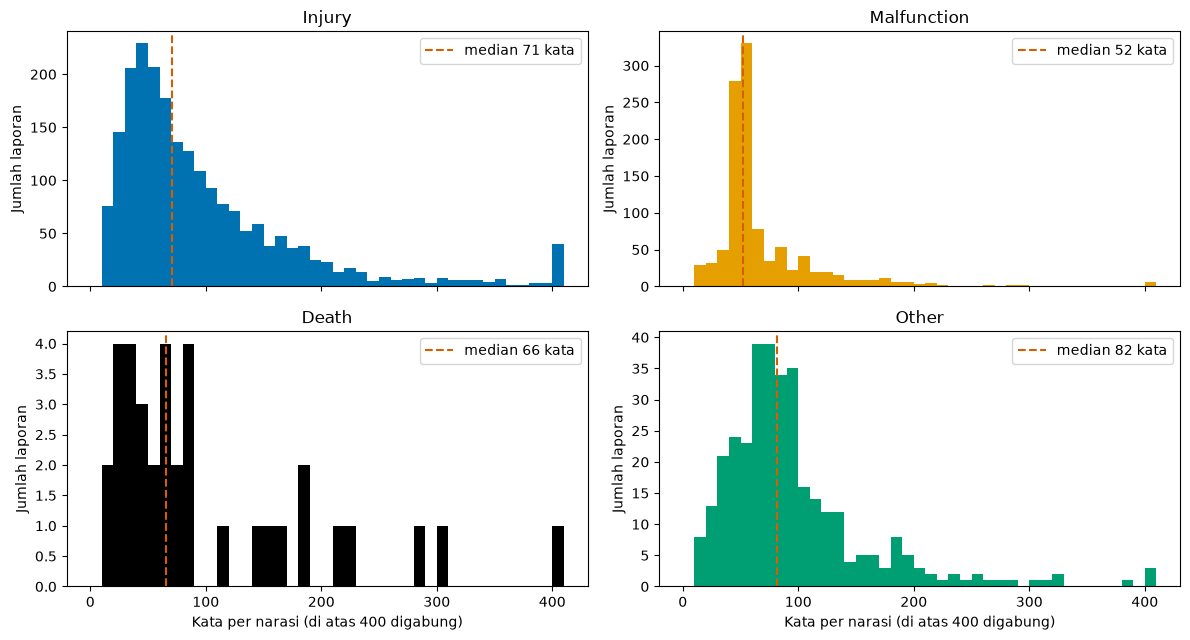

,count,mean,std,min,25%,50%,75%,max
event_type,,,,,,,,
Injury,2144.0,101.1,103.5,10.0,44.0,71.0,123.0,1181.0
Malfunction,1082.0,70.0,60.3,10.0,48.0,52.0,72.8,937.0
Death,36.0,106.8,116.0,11.0,37.5,65.5,148.5,618.0
Other,342.0,97.8,77.2,11.0,58.0,82.0,111.0,718.0


In [21]:
n_kata = df.event_text.str.split().str.len().rename("n_kata")
ringkas = n_kata.groupby(df.event_type).describe().loc[KELAS].round(1)
ringkas.to_csv(TABEL / "02_panjang_narasi.csv")

fig, axes = plt.subplots(2, 2, figsize=(12, 6.5), sharex=True)
for ax, k, w in zip(axes.flat, KELAS, WARNA):
    v = n_kata[df.event_type == k]
    ax.hist(v.clip(upper=400), bins=np.arange(0, 411, 10), color=w)
    ax.axvline(v.median(), color="#D55E00", ls="--", label=f"median {v.median():.0f} kata")
    ax.set(title=k, ylabel="Jumlah laporan")
    ax.legend()
for ax in axes[1]:
    ax.set_xlabel("Kata per narasi (di atas 400 digabung)")
fig.tight_layout()
fig.savefig(GAMBAR / "02_panjang_narasi.png", dpi=150)
plt.show()
ringkas

### Contoh narasi dan pabrikan

In [22]:
contoh = pd.concat([df[df.event_type == k].sample(2, random_state=42) for k in KELAS])
contoh = contoh[["event_type", "mdr_report_key", "event_text"]]
contoh.to_csv(TABEL / "02_contoh_narasi.csv", index=False)
for r in contoh.itertuples():
    print(f"[{r.event_type}] {r.mdr_report_key}\n{r.event_text[:500]}\n")

top = df.manufacturer.value_counts().head(10)
top.to_csv(TABEL / "02_top_manufacturer.csv")
top

[Injury] 8590861
THE PATIENT WAS IN THE POST ANESTHESIA CARE UNIT (PACU) IMMEDIATELY AFTER SURGERY AND A REDDENED AREA WAS NOTED ON HIS LEFT LATERAL MID-FOREARM. A COLD COMPRESS WAS APPLIED. THE SITE WAS ASSESSED WITHIN THE HOUR, WHILE THE PATIENT REMAINED IN THE PACU AND THE SITE HAD A HARD AREA AND FORMED A DIME-SIZED BLISTER IN THE MIDDLE OF THE WOUND. MANUFACTURER RESPONSE FOR MRI ANTERIOR COIL, MRI ANTERIOR COIL (PER SITE REPORTER). THE MRI DIRECTOR WAS ALERTED TO THIS PATIENT BURN. HE DEPLOYED THE IMAGING 

[Injury] 22214104
DESCRIPTION OF PROBLEM: I UNDERWENT A SCHEDULED MAGNETIC RESONANCE IMAGING (MRI) OF MY TEMPORAL LOBES WITH CONTRAST AT (B)(6). I HAVE A HISTORY OF STROKE AND POST-TRAUMATIC STRESS DISORDER (PTSD) AND RECEIVE REGULAR MRIS, ALL WITHOUT EVER HAVING AN ISSUE. DURING THIS SCAN, I EXPERIENCED THE ONSET OF A PANIC ATTACK WHILE INSIDE THE MRI MACHINE. I ATTEMPTED TO USE THE EMERGENCY SQUEEZE BULB PROVIDED TO SIGNAL STAFF AND REQUEST TO BE REMOVED. DESPITE SQUEEZING I

manufacturer
GE MEDICAL SYSTEMS, LLC                   626
PHILIPS ELECTRONICS NEDERLAND B.V.        469
PHILIPS HEALTHCARE                        338
PHILIPS MEDICAL SYSTEMS NEDERLAND B.V.    242
PHILIPS MEDICAL SYSTEMS                   240
GE MEDICAL SYSTEMS                        146
SIEMENS HEALTHCARE GMBH                   112
UNK                                       102
SIEMENS HEALTHINEERS AG                    94
                                           65
Name: count, dtype: int64

In [23]:
# Angka pada "Temuan" di bawah dihitung di sini supaya bisa dicek ulang
def philips_2025_mal(d):
    m = (d.date_received.str[:4].eq("2025")
         & d.manufacturer.str.contains("philips", case=False)
         & d.event_type.eq("Malfunction"))
    return int(m.sum())

awal, akhir = philips_2025_mal(mentah), philips_2025_mal(df)
print(f"Malfunction Philips 2025: {awal} (mentah) -> {akhir} (bersih)")

th = df.date_received.str[:4].astype(int)
other_th = th[df.event_type.eq("Other") & th.ge(2010)].value_counts().sort_index()
print("Other per tahun sejak 2010:", other_th.to_dict())
baru = df[th.ge(2024)].event_type.value_counts()
print("2024-2026 -> Death:", baru.get("Death", 0), "| Other:", baru.get("Other", 0))

assert (awal, akhir) == (1110, 363)
assert (baru.get("Death", 0), baru.get("Other", 0)) == (4, 12)


Malfunction Philips 2025: 1110 (mentah) -> 363 (bersih)
Other per tahun sejak 2010: {2010: 35, 2011: 9, 2012: 11, 2013: 6, 2014: 1, 2016: 1, 2024: 1, 2025: 1, 2026: 10}
2024-2026 -> Death: 4 | Other: 12


### Temuan untuk laporan (angka dari sel di atas)
1. **Ketimpangan berat.** Death hanya 36 laporan (1,0%) dan Other 342 (9,5%).
2. **Other turun tajam setelah 2010, tetapi tidak langsung hilang.** Setelah pembersihan jumlahnya
   35 (2010), 9 (2011), 11 (2012), 6 (2013), lalu 0–1 per tahun selama 2014–2025, dan muncul lagi
   10 laporan pada 2026.
3. **Lonjakan 2025 berasal dari template Philips.** Malfunction Philips 2025 turun dari 1.110
   menjadi 363 setelah penyaringan dan deduplikasi.
4. **Pembersihan paling banyak mengurangi Malfunction** (2.104 menjadi 1.082), sedangkan Death
   hanya berkurang satu.
5. **Pergeseran waktu.** Periode 2024–2026 hanya memuat 4 Death dan 12 Other, sehingga skor
   kedua kelas itu pada validasi temporal akan rapuh.

## Simpan dan cek akhir tahap 1

In [24]:
acuan = {"Injury": 2144, "Malfunction": 1082, "Death": 36, "Other": 342}
assert len(df) == 3604
assert df.event_type.value_counts().to_dict() == acuan
assert df.norm.is_unique and df.mdr_report_key.is_unique
assert df.event_type.ne("").all()
assert df.grup.notna().all()

df.to_csv(ROOT / "data/interim/data_bersih.csv", index=False)
print("Semua cek akhir tahap 1 lolos")

Semua cek akhir tahap 1 lolos
